# Groepsindeling 8×8 met vaste schaal ×64 / A32 — honderd epochs

Deze proef vergelijkt **8×8-groepen met de bestaande 1×32- en 1×64-groepen**, steeds met vaste ×64 voor de lagere precisies. De matrix van iedere MX-laag heeft outputkanalen op de rijen en afgevlakte `Cin × Kh × Kw`-posities op de kolommen. Een groep bevat acht rijen × acht kolommen: 64 gewichten met één E8M0-bronschaal. Beide matrixassen worden waar nodig met positieve nullen aangevuld.

E4M3 wordt uit de actuele effectieve FP32-gewichten G(W) bepaald. E2M3 behoudt de hoogste twee exponentbits en gebruikt **E8M0-broncode +6**. E2M1 verwijdert daarna twee mantissabits van E2M3 en behoudt dezelfde E2M3-schaal. Eén E4M3-bron wordt per laag en minibatch gedeeld door de drie modi. Activaties zijn **A32**; de updatemaster, gradients en Adam-momenten zijn **FP32**. Er zijn geen geleerde schaalparameters.

**De hoofdfiguren tonen epoch 100 en het gezamenlijke checkpoint gekozen door de hoogste E4M3-accuracy.** Alle drie scores komen steeds uit dezelfde epoch. De volledige accuracycurves vergelijken de drie groepsindelingen over epochs 1–100. Bij een onvoltooide run blijven alleen de gezamenlijke gemeten epochs zichtbaar; epoch 100 wordt niet als eindresultaat ingevuld.

**Nieuwe initialisatie:** deze honderd-epochtraining begint opnieuw met dezelfde seed en oorspronkelijke modelstaat. De geslaagde vijf-epochpilot is afzonderlijk bewaard in `pilot_analysis`; de pilotepochs worden niet aan deze run toegevoegd en de pilotcheckpoint wordt niet hervat.

De kostenanalyse toont apart het aantal schalen, de padding en de totale code- en schaalbytes voor 1×32, 1×64 en 8×8. Dit notebook leest uitsluitend opgeslagen JSON/CSV en rekent geometrische opslagkosten na. Het laadt geen dataset, model, checkpoint of optimizer en start geen training.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_group8x8_scale64_reference100\\20261028_190237_184325_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_group8x8_scale64_reference100_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **100**.

**Alle honderd epochs voor alle drie modi aanwezig; volledige referentie volgens het runrapport.** Epoch100 staat naast het door E4M3 gekozen beste checkpoint.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,E4M3-bron uit actueel G(W) → E2M3 via exponent...
2,Schaal bij lagere modi,E4M3-broncode +6 in E8M0 (×64); E2M1 behoudt d...
3,Schaalgrenzen,Offset in breder integer-type; buiten eindig E...
4,STE,Identity door de volledige codebewerking naar ...
5,Schaal tijdens training,Bron wordt opnieuw bepaald uit actuele gewicht...
6,BatchNorm,Eigen doelbank per modus leert mee tijdens tra...
7,Schaalbeleid,encode current E4M3 source scale floor(log2(am...
8,Activaties / updatemaster,A32 / float32
9,Distillatie,E4M3 hard CE + E2M3 soft CE from detached E4M3...


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Twee checkpointkeuzes: epoch 100 en het beste E4M3-checkpoint

**Epoch 100** is het vooraf gekozen vaste eindpunt. Het **beste checkpoint** is de eerste epoch met de hoogste E4M3-testaccuracy binnen de beschikbare geschiedenis. E2M3 en E2M1 worden op datzelfde checkpoint getoond; zij kiezen geen eigen beste epoch.

De tabel bewaart daarnaast de laatste beschikbare epoch. Bij een gedeeltelijke of niet bevestigde volledige run blijft de epoch-100-rij leeg en toont de linkerfiguur de laatste werkelijk gemeten epoch, duidelijk als voorlopig eindpunt. Het beste checkpoint wordt dan uitsluitend binnen die beschikbare epochs gekozen.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Laatste beschikbare epoch,100,MXFP8_E4M3,94.921635,24.710 / 26.032,0.206597,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Laatste beschikbare epoch,100,MXFP6_E2M3,94.625845,24.633 / 26.032,0.191309,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Laatste beschikbare epoch,100,MXFP4_E2M1,94.552858,24.614 / 26.032,0.194720,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3,51,MXFP8_E4M3,95.036878,24.740 / 26.032,0.194982,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3,51,MXFP6_E2M3,94.383835,24.570 / 26.032,0.199283,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3,51,MXFP4_E2M1,94.264751,24.539 / 26.032,0.206836,checkpoint_selection.json,best_checkpoint.pt
6,epoch100,Vast eindpunt epoch100,100,MXFP8_E4M3,94.921635,24.710 / 26.032,0.206597,alle drie modi; volledige referentie bevestigd,niet gerapporteerd
7,epoch100,Vast eindpunt epoch100,100,MXFP6_E2M3,94.625845,24.633 / 26.032,0.191309,alle drie modi; volledige referentie bevestigd,niet gerapporteerd
8,epoch100,Vast eindpunt epoch100,100,MXFP4_E2M1,94.552858,24.614 / 26.032,0.194720,alle drie modi; volledige referentie bevestigd,niet gerapporteerd


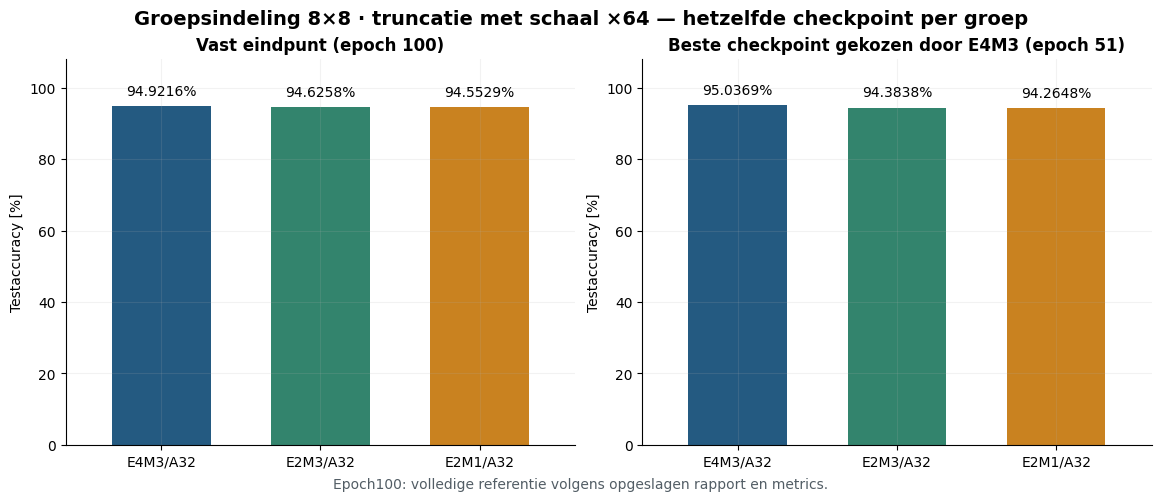

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met 1×32 en 1×64: accuracy over de volledige training

De vastgelegde 1×32- en 1×64-referenties bevatten hun voltooide honderd-epochtrainingen. De figuren vergelijken de **curves over epochs 1–100**, **epoch 100** en het **gezamenlijke beste E4M3-checkpoint**. Referentiehashes, oorspronkelijke modelinitialisatie en trainingsinstellingen worden gecontroleerd voordat scores naast elkaar verschijnen.

Bij een gedeeltelijke 8×8-run stoppen alle curves bij de laatste beschikbare 8×8-epoch. Ook de beste-checkpointkeuze wordt dan voor iedere training beperkt tot diezelfde gezamenlijke epochrange. De epoch-100-vergelijking verschijnt uitsluitend als de nieuwe 8×8-run volledig en consistent is afgerond. De eerdere vijf-epochpilot vormt een apart resultaat en wordt niet samengevoegd met deze nieuwe training.

**1×64 tegenover 8×8 vergelijkt hetzelfde aantal gewichten per gedeelde schaal met een andere groepsvorm.** De vergelijking met 1×32 verandert zowel de groepsvorm als het aantal gewichten per groep. De ×64-schaalroute blijft in alle gevallen gelijk. Per training komen alle drie scores uit de epoch die door E4M3 gekozen is.


### Groepsindelingen 8×8, 1×32 en 1×64 met dezelfde vaste ×64

De 1×32- en 1×64-cijfers komen uit hun bestaande volledige honderd-epochtrainingen. Deze nieuwe 8×8-run begint opnieuw vanaf initialisatie; de eerdere pilot is afzonderlijk bewaard. Epoch 100 en het gezamenlijke beste E4M3-checkpoint zijn de twee hoofdvergelijkingen. Bij een onvoltooide run kiest E4M3 per training één checkpoint binnen de gezamenlijke gemeten epochrange; alle drie scores komen uit diezelfde epoch. 

**Vergelijking met 1×32, 1×64 beschikbaar voor epochs 1–100.** Dezelfde oorspronkelijke modelstaat, seed en behouden trainingsinstellingen zijn bevestigd. Alle varianten gebruiken vaste ×64. 1×64 en 8×8 bevatten beide 64 gewichten per schaal; hun groepsvorm verschilt. Dit garandeert geen bitexacte CUDA-herhaalbaarheid. Zonder bevestigde volledige 8×8-run blijft de epoch-100-vergelijking leeg.

,Controlepunt,Groepsindeling,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Verschil 8×8 − referentie [pp]
0,Epoch 100,8×8,100,MXFP8_E4M3,94.921635,24.710 / 26.032,0.206597,NaN
1,Epoch 100,1×32,100,MXFP8_E4M3,94.929318,24.712 / 26.032,0.209868,-0.007683
2,Epoch 100,1×64,100,MXFP8_E4M3,94.691149,24.650 / 26.032,0.217980,0.230486
3,Epoch 100,8×8,100,MXFP6_E2M3,94.625845,24.633 / 26.032,0.191309,NaN
4,Epoch 100,1×32,100,MXFP6_E2M3,94.898586,24.704 / 26.032,0.189969,-0.272741
5,Epoch 100,1×64,100,MXFP6_E2M3,94.545175,24.612 / 26.032,0.196793,0.080670
6,Epoch 100,8×8,100,MXFP4_E2M1,94.552858,24.614 / 26.032,0.194720,NaN
7,Epoch 100,1×32,100,MXFP4_E2M1,94.791026,24.676 / 26.032,0.193797,-0.238168
8,Epoch 100,1×64,100,MXFP4_E2M1,94.510602,24.603 / 26.032,0.197544,0.042256
9,Beste E4M3 binnen epochs 1–100,8×8,51,MXFP8_E4M3,95.036878,24.740 / 26.032,0.194982,NaN


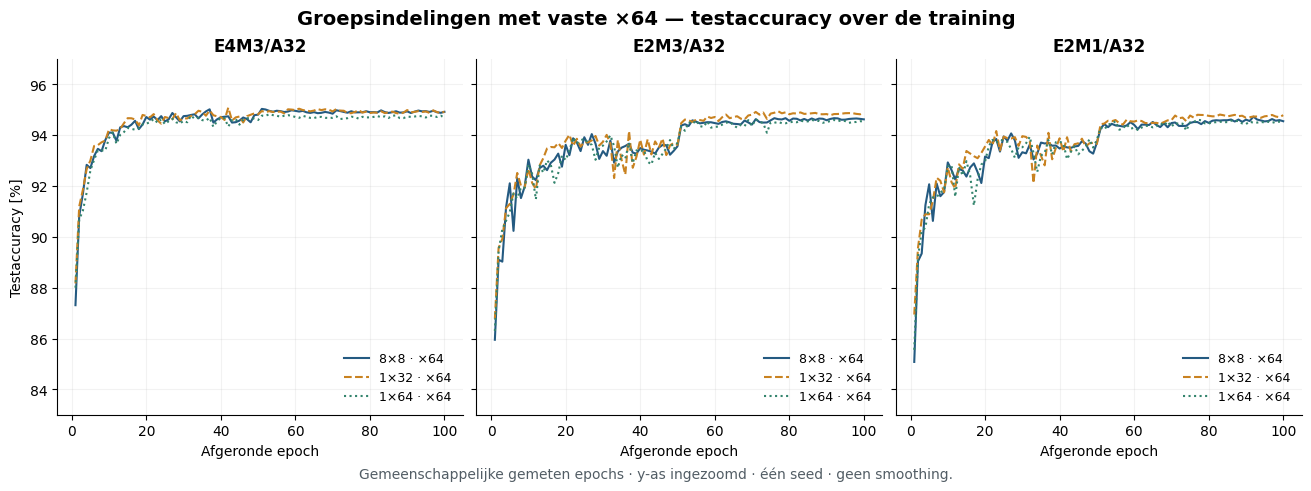

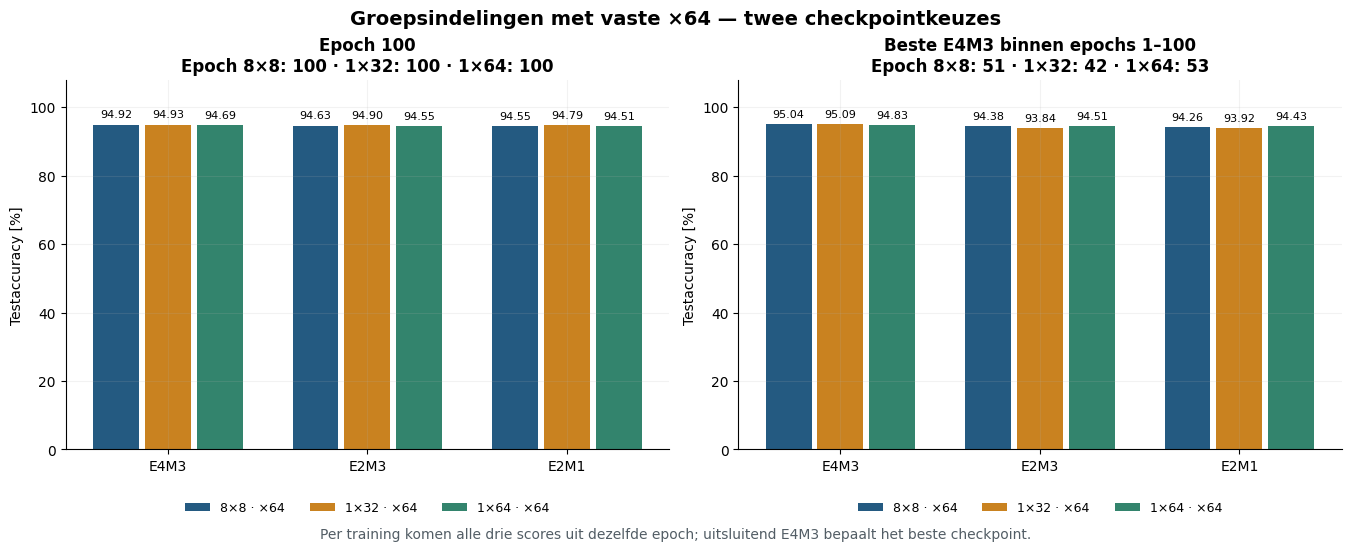

In [4]:
references = ns.load_group_references(run)
display(Markdown(ns.comparison_markdown(run, references)))
display(ns.comparison_table(run, references).round(6))
figures['group_comparison_curves'] = ns.plot_scale_comparison_curves(run, references)
display(figures['group_comparison_curves'])
plt.close(figures['group_comparison_curves'])
figures['group_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, references)
display(figures['group_comparison_checkpoints'])
plt.close(figures['group_comparison_checkpoints'])


## Kosten: aantal schalen, padding en totale opslag

Elke groep heeft één E8M0-schaal van acht bits. Zonder padding kost de schaal 0,25 bits per gewicht bij 1×32 en 0,125 bits bij zowel 1×64 als 8×8. Bij 1D-groepen wordt iedere outputrij tot een veelvoud van 32 of 64 aangevuld; bij 8×8 worden beide matrixassen tot veelvouden van acht aangevuld.

De berekening gebeurt per laag en per precisie. Voor E4M3 tonen we de afzonderlijke overhead van schaalbytes en paddingcodes bovenop de reële gewichtswaarden. **Voor deze zes laagvormen heeft 8×8 slechts 64 paddingposities**, tegenover 1.088 bij 1×32 en 8.768 bij 1×64. Dit kostenverschil is vooraf exact uit de vormen berekenbaar en zegt nog niets over de accuracy.


Het opgeslagen geometrische kostenrapport is opnieuw berekend en bevestigd. Voor **6 van de 6** verwachte exporttabellen (drie precisies × beste/laatste checkpoint) zijn de gerapporteerde 8×8-groepen, padding en payload bevestigd.

De totalen betreffen uitsluitend de **129.472 reële gewichten in de zes MX-lagen**. E4M3 is de opgeslagen bron; E2M3/E2M1 zijn afzonderlijke mogelijke afgeleide exports. **Tel de drie payloadgroottes niet bij elkaar op als de opslag van één bronmodel.** Elke groep heeft één gedeelde schaal van acht bits; bij de vaste ×64-correctie wordt geen geleerde keuze per groep opgeslagen.

Bij 8×8 worden beide assen van de gewichtsmatrix tot veelvouden van acht aangevuld. Deze zes lagen vragen samen 2.024 schalen en 64 paddingposities. 1×64 gebruikt 2.160 schalen en 8.768 paddingposities; 1×32 gebruikt 4.080 schalen en 1.088 paddingposities. Dit is een geometrisch resultaat, onafhankelijk van de nog te meten accuracy.

FP32-uitzonderingen/BatchNorm, optimizer, bestandsmetadata en emulatorbuffers zijn uitgesloten. De oorspronkelijke exports bewaren alle vijf BN-banken; de recente inference-transferproef telde alleen ondersteunde banken. Deze logische code- en schaalbytes zijn geen checkpointbestandsgrootte, GPU-geheugenmeting, hardwarelooptijd of energiemeting.

,Groepsindeling,Gewichten per groep,Reële gewichten,Groepen / schalen,Paddingposities,Schaalbytes,Schaalbits/gewicht zonder padding,E4M3 bron + schalen [bytes],E2M3 + schalen [bytes],E2M1 + schalen [bytes],E4M3 effectieve bits/reëel gewicht,E2M3 effectieve bits/reëel gewicht,E2M1 effectieve bits/reëel gewicht
0,1×32,32,129472,4080,1088,4080,0.250,134640,102000,69360,8.319328,6.302521,4.285714
1,1×64,64,129472,2160,8768,2160,0.125,140400,105840,71280,8.675235,6.539792,4.404350
2,8×8,64,129472,2024,64,2024,0.125,131560,99176,66792,8.129016,6.128028,4.127039


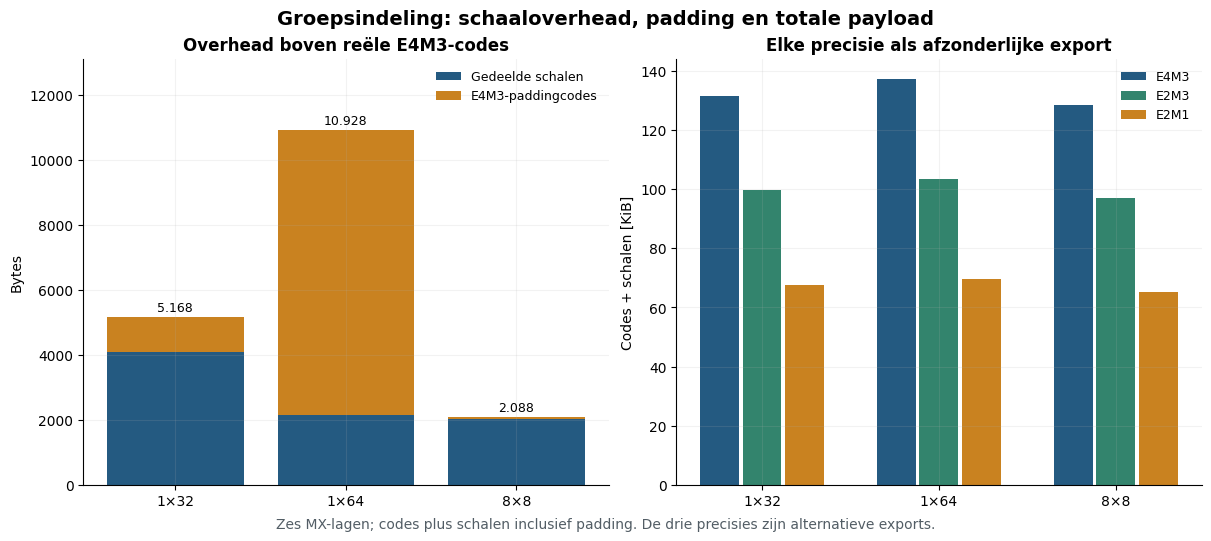

In [5]:
display(Markdown(ns.cost_markdown(run)))
display(ns.cost_summary_table(run).round(6))
figures['group_size_costs'] = ns.plot_group_costs(run)
display(figures['group_size_costs'])
plt.close(figures['group_size_costs'])


### Kosten per laag en controle tegen de opgeslagen exports

De eerste tabel geeft de berekende E4M3-bronindeling per laag voor 1×32, 1×64 en 8×8. De lagere precisies worden met dezelfde groepsgeometrie afzonderlijk berekend. `group_size_costs_layers.csv` bevat alle lagen en alle drie de precisies.

De tweede tabel controleert de **8×8-indeling** tegen de opgeslagen exportdiagnostiek op het beste en laatste checkpoint. Deze controle bevestigt gerapporteerde aantallen; de codec- en exporttests van de runner controleren daarnaast de werkelijke codebytes, padding op beide matrixassen en gereconstrueerde gewichten. Het label 64 gewichten per groep alleen volstaat niet om 1×64 van 8×8 te onderscheiden.


In [6]:
display(ns.cost_layer_table(run, weight_bits=8))
display(ns.export_layout_table(run))


,Indeling,Laag,Vorm,Outputrijen,Opgeslagen outputrijen,Gewichten/rij,Opgeslagen/rij,Reële gewichten,Groepen,Paddingposities,Codebytes,Schaalbytes,Code + schaal [bytes]
0,1×32,layers.3,"[16, 12, 3, 3]",16,16,108,128,1728,64,320,2048,64,2112
1,1×32,layers.6,"[16, 16, 3, 3]",16,16,144,160,2304,80,256,2560,80,2640
2,1×32,layers.10,"[32, 16, 3, 3]",32,32,144,160,4608,160,512,5120,160,5280
3,1×32,layers.13,"[32, 32, 3, 3]",32,32,288,288,9216,288,0,9216,288,9504
4,1×32,layers.16,"[32, 32, 3, 3]",32,32,288,288,9216,288,0,9216,288,9504
5,1×32,layers.20,"[128, 32, 5, 5]",128,128,800,800,102400,3200,0,102400,3200,105600
6,1×64,layers.3,"[16, 12, 3, 3]",16,16,108,128,1728,32,320,2048,32,2080
7,1×64,layers.6,"[16, 16, 3, 3]",16,16,144,192,2304,48,768,3072,48,3120
8,1×64,layers.10,"[32, 16, 3, 3]",32,32,144,192,4608,96,1536,6144,96,6240
9,1×64,layers.13,"[32, 32, 3, 3]",32,32,288,320,9216,160,1024,10240,160,10400


,status,reported_layout_verified,group_size,layout,weight_bits,layers,n_weights,blocks,padded_slots,packed_weight_and_scale_bytes,role,epoch
0,PASS,True,64,tile8x8,8,6,129472,2024,64,131560,best,51
1,PASS,True,64,tile8x8,6,6,129472,2024,64,99176,best,51
2,PASS,True,64,tile8x8,4,6,129472,2024,64,66792,best,51
3,PASS,True,64,tile8x8,8,6,129472,2024,64,131560,last,100
4,PASS,True,64,tile8x8,6,6,129472,2024,64,99176,last,100
5,PASS,True,64,tile8x8,4,6,129472,2024,64,66792,last,100


## Kwantisatiefout op de twee geselecteerde checkpoints

De opgeslagen exportdiagnostiek vergelijkt de gecodeerde gewichten met de effectieve FP32-gewichten G(W), zonder een nieuwe evaluatie te starten. RMSE wordt gewogen over de reële gewichten van de zes MX-lagen; padding telt niet mee. Nieuwe nulwaarden zijn gewichten die vóór kwantisatie niet nul waren en daarna nul worden. Dit is gewichtsdiagnostiek, geen vervanging voor testaccuracy.


,checkpoint_role,checkpoint_epoch,weight_bits,layer,n_weights,mae,rmse,relative_l2,max_abs_error,new_zero_count,local_subnormal_count,out_of_element_range_before_round,scale_exponent_min,scale_exponent_max,padded_slots
0,best,51,8,layers.3,1728,0.002111,0.002973,0.027293,0.007810,1,0,0,-11,-11,64
1,best,51,8,layers.6,2304,0.002247,0.003171,0.031908,0.007811,0,1,0,-11,-11,0
2,best,51,8,layers.10,4608,0.002054,0.002946,0.030153,0.007811,0,1,0,-11,-11,0
3,best,51,8,layers.13,9216,0.001884,0.002775,0.030850,0.007812,0,1,0,-11,-11,0
4,best,51,8,layers.16,9216,0.001545,0.002341,0.028510,0.007810,0,2,0,-11,-11,0
5,best,51,8,layers.20,102400,0.000900,0.001510,0.029663,0.015591,2,11,313,-12,-11,0
6,best,51,6,layers.3,1728,0.063101,0.085880,0.788406,0.205939,3,1,0,-5,-5,64
7,best,51,6,layers.6,2304,0.070034,0.089980,0.905372,0.205781,0,3,0,-5,-5,0
8,best,51,6,layers.10,4608,0.071394,0.090743,0.928638,0.205932,0,2,0,-5,-5,0
9,best,51,6,layers.13,9216,0.079776,0.097037,1.078817,0.206047,0,13,0,-5,-5,0


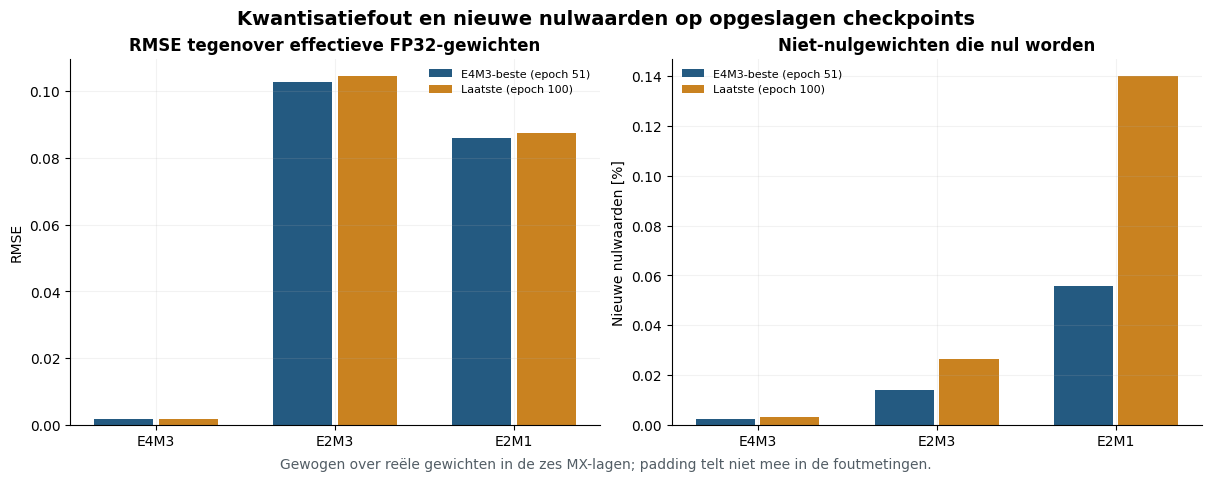

In [7]:
display(ns.quantization_table(run))
figures['quantization_diagnostics'] = ns.plot_quantization(run)
display(figures['quantization_diagnostics'])
plt.close(figures['quantization_diagnostics'])


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf dezelfde oorspronkelijke initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met **8×8-groepen** en dezelfde ×64-truncatieroute, bevroren evaluatiestaat en de volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee.


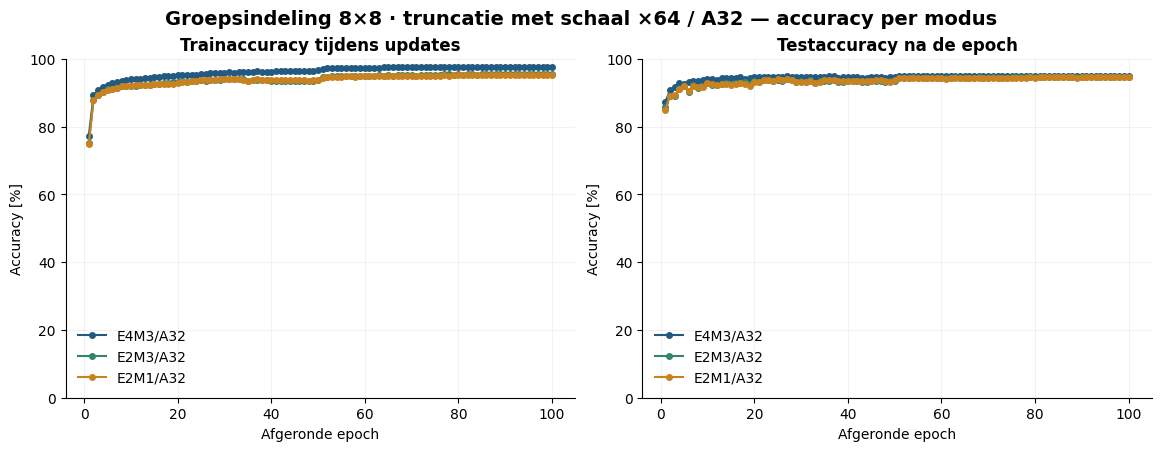

In [8]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.937855
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.909735
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.707607
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.491888
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.456200
...,...,...,...,...,...
595,100,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.183155
596,100,train,MXFP8_E4M3,hard_cross_entropy,0.078017
597,100,test,MXFP4_E2M1,hard_cross_entropy,0.194720
598,100,test,MXFP6_E2M3,hard_cross_entropy,0.191309


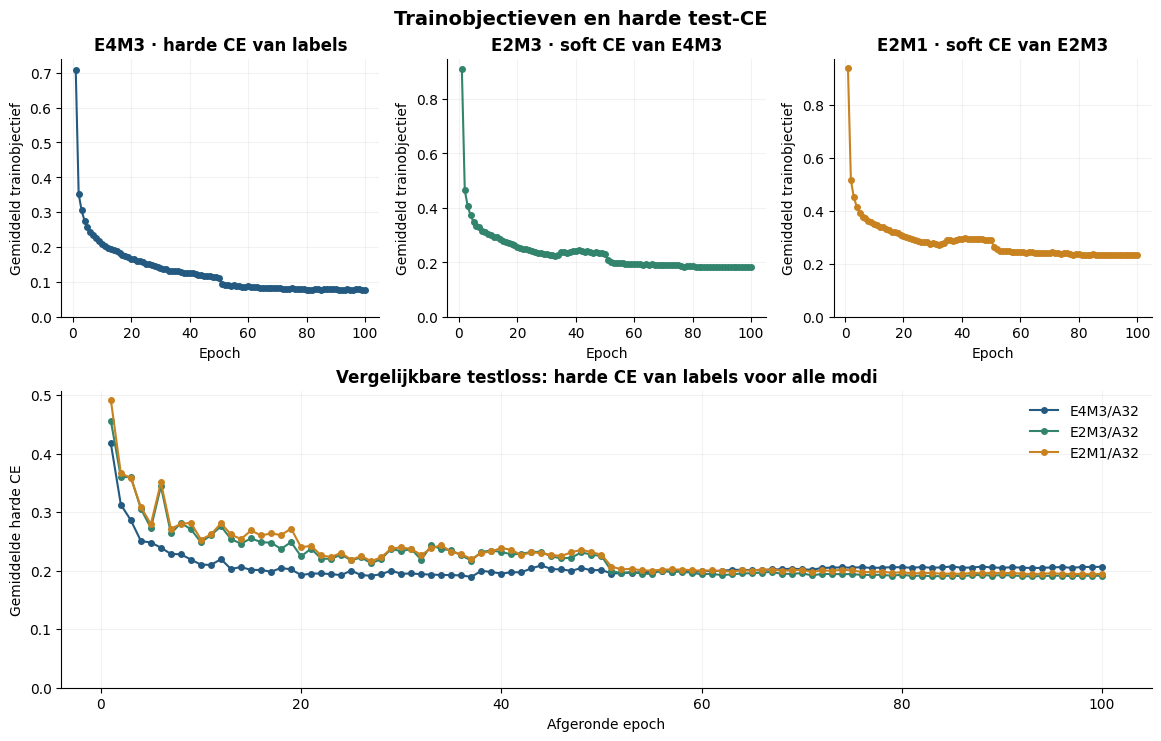

In [9]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,100,MXFP8_E4M3,10,1,19.890904,19.587431,94.921635,False,26032,"[1781, 5178, 4124, 2855, 2493, 2348, 1967, 202...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,100,MXFP6_E2M3,10,1,19.837124,19.587431,94.625845,False,26032,"[1803, 5164, 4138, 2825, 2533, 2317, 1969, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,100,MXFP4_E2M1,10,1,19.879379,19.587431,94.552858,False,26032,"[1815, 5175, 4149, 2823, 2527, 2310, 1957, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,51,MXFP8_E4M3,10,1,19.867855,19.587431,95.036878,False,26032,"[1773, 5172, 4117, 2864, 2489, 2374, 1967, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,51,MXFP6_E2M3,10,1,19.902428,19.587431,94.383835,False,26032,"[1772, 5181, 4107, 2866, 2497, 2347, 1978, 199...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,51,MXFP4_E2M1,10,1,19.840965,19.587431,94.264751,False,26032,"[1778, 5165, 4120, 2836, 2504, 2329, 1954, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


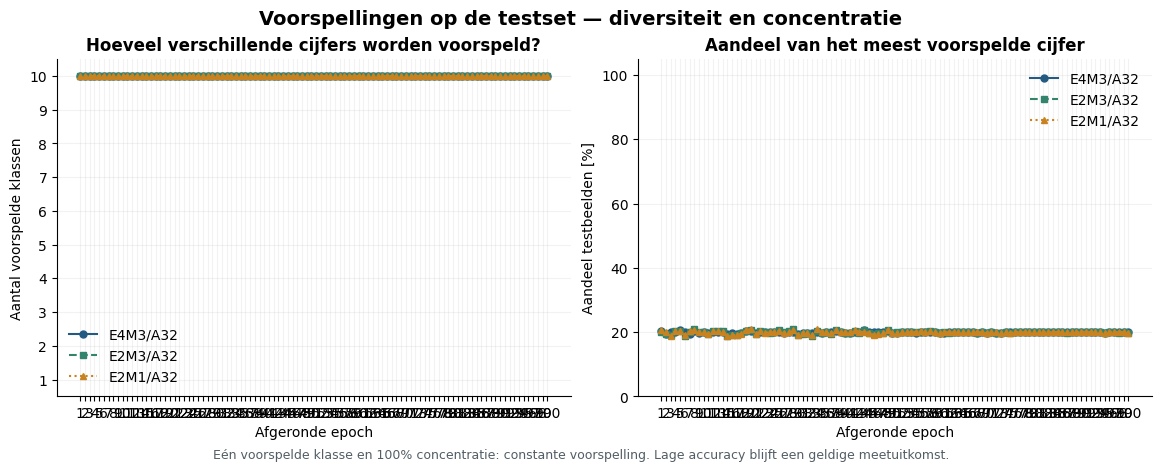

In [10]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Gemeten trainingsduur en CUDA-geheugen

Na een bevestigde volledige run wordt de **gemeten som van de honderd epochtijden** getoond, met train, test, controles en checkpointschrijven afzonderlijk. Bij een gedeeltelijke run blijft een eventueel opgeslagen tijdprojectie duidelijk een schatting voor een nieuwe volledige run; er wordt geen ontbrekende accuracy voorspeld.

De geheugenfiguur betreft het werkelijke CUDA-allocatorgebruik van deze FP32-emulator. De logische MX-code- en schaalpayload staat afzonderlijk in de kostenanalyse.


**Gemeten som over 100 afgeronde epochs: 6057.46 s (100.96 minuten).** Alle honderd epochs zijn aanwezig. De gemeten duur omvat train, test, epochcontroles en checkpointschrijven; een eerdere projectie wordt hiervoor niet gebruikt. Download, installatie, data-inladen, eindrapportage en sessiepauzes zijn niet inbegrepen.

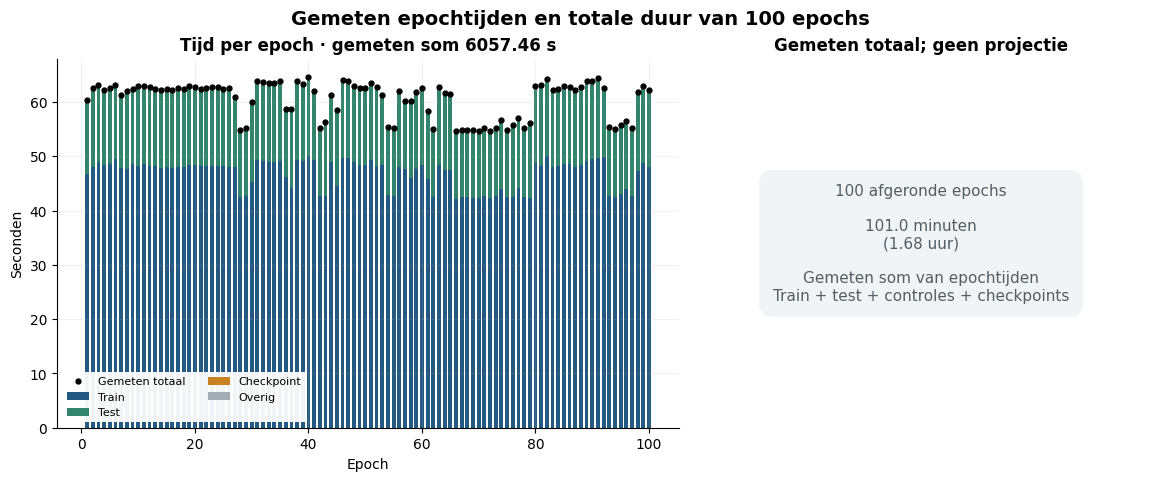

In [11]:
display(Markdown('## Gemeten trainingsduur en CUDA-geheugen\n\nNa een bevestigde volledige run wordt de **gemeten som van de honderd epochtijden** getoond, met train, test, controles en checkpointschrijven afzonderlijk. Bij een gedeeltelijke run blijft een eventueel opgeslagen tijdprojectie duidelijk een schatting voor een nieuwe volledige run; er wordt geen ontbrekende accuracy voorspeld.\n\nDe geheugenfiguur betreft het werkelijke CUDA-allocatorgebruik van deze FP32-emulator. De logische MX-code- en schaalpayload staat afzonderlijk in de kostenanalyse.\n'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

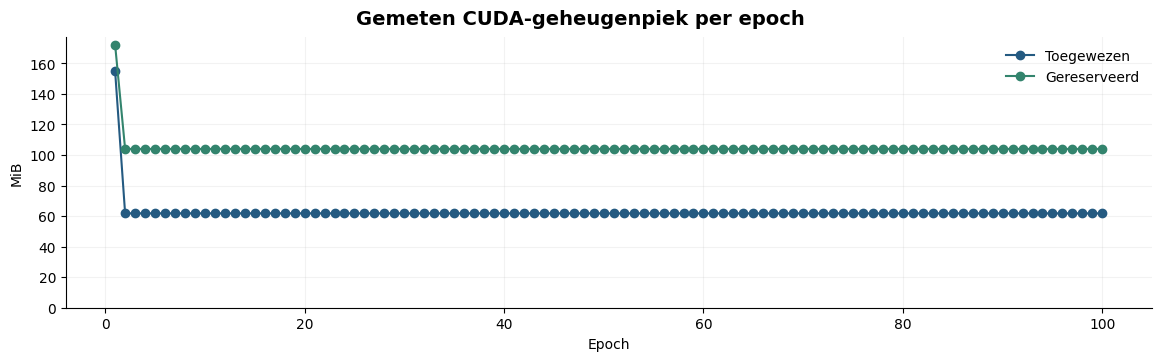

In [12]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [13]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,Lagere schaalcodes exact E4-bron +6,True
3,E2M1 behoudt de E2M3-schaalbytes,True
4,Eén E4-bron per laag per minibatch,True
5,Broncache leeg vóór iedere optimizerupdate,True
6,BN-tellers van alle opgeslagen epochs correct,True
7,Geen optimizerupdates tijdens evaluatie,True
8,Bronbestanden onveranderd,True
9,Ruwe datasetbestanden onveranderd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.399588,torch.float32,1079,0
1,1,MXFP6_E2M3,layers.3,1728,1.399588,torch.float32,1540,0
2,1,MXFP8_E4M3,layers.3,1728,1.399588,torch.float32,1616,0
3,1,MXFP4_E2M1,layers.6,2304,1.716067,torch.float32,1430,0
4,1,MXFP6_E2M3,layers.6,2304,1.716067,torch.float32,2071,0
...,...,...,...,...,...,...,...,...
1795,100,MXFP6_E2M3,layers.16,9214,0.002016,torch.float32,189,0
1796,100,MXFP8_E4M3,layers.16,9214,0.002016,torch.float32,192,0
1797,100,MXFP4_E2M1,layers.20,96755,0.006642,torch.float32,247,0
1798,100,MXFP6_E2M3,layers.20,96755,0.006642,torch.float32,811,0


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes FP32-masters afwezig,Volledige exporttest opnieuw,Truncatie,Bron of afleiding,E4-bronschaalbytes behouden,Schaalexponentoffset tegenover E4,Schaalfactor tegenover E4,Masters gelezen voor afleiding,Opgeslagen en herladen,Bronbestand-SHA256
0,best_E4M3_test,51,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,193829,True,True,False,False,E4M3-bron,True,0,1,False,True,850b99c7dca32c41c47559430ea388f8ba5d3af0212147...
1,best_E4M3_test,51,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,162085,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,850b99c7dca32c41c47559430ea388f8ba5d3af0212147...
2,best_E4M3_test,51,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,129701,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,850b99c7dca32c41c47559430ea388f8ba5d3af0212147...
3,last_epoch,100,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,193829,True,True,False,False,E4M3-bron,True,0,1,False,True,294a67bf518e439f5593689fa586e3022f09d146035d40...
4,last_epoch,100,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,162085,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,294a67bf518e439f5593689fa586e3022f09d146035d40...
5,last_epoch,100,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,129701,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,294a67bf518e439f5593689fa586e3022f09d146035d40...


## Interpretatie en grenzen

De gerichte wijziging is **8×8-groepering** tegenover de bestaande 1×64- en 1×32-referenties. De factor blijft ×64, mantissatruncatie behoudt de E2M3-schaal, en de overige trainingsinstellingen en initiële mastergewichten komen overeen. De identity-STE geldt voor de volledige codebewerking naar G(W), zonder extra factor 64 in de backward.

Een 8×8-groep deelt de schaal tussen verschillende outputfilters. Dat kan de quantisatiefout en accuracy veranderen; minder padding garandeert geen betere accuracy. Een lage accuracy blijft een onderzoeksuitkomst wanneer de technische controles slagen. Bekijk testaccuracy, harde test-CE en voorspellingstellingen samen.

De hardwaremotivatie is dat een vierkant blok dezelfde 64 gewichten blijft bevatten bij transpositie. De codeccontrole toetst die eigenschap en de bijbehorende schalen. Deze training emuleert de convoluties in FP32 en bewijst op zichzelf geen snelheids-, transfer- of energiewinst. Zie Cuyckens et al., *Efficient Precision-Scalable Hardware for Microscaling (MX) Processing in Robotics Learning*, §IV-A: https://arxiv.org/html/2505.22404v2.

De oorspronkelijke cuDNN-backend garandeert geen bitexacte CUDA-herhaalbaarheid. Deze proef heeft één seed; een klein accuracyverschil bewijst geen algemene superioriteit of optimale groepsindeling. Het beste E4M3-checkpoint wordt op de officiële testset geselecteerd en is geen onafhankelijke testschatting na selectie. Het vaste eindpunt epoch 100 blijft daarom afzonderlijk zichtbaar.

**Kosten horen bij de conclusie:** rapporteer schaalbytes, padding en totale code- en schaalpayload afzonderlijk. De drie exportgroottes zijn alternatieven; één E4M3-bronmodel wordt niet driemaal geteld. De oorspronkelijke compacte exports bewaren ook FP32-uitzonderingen en alle vijf BN-banken; de code- en schaaltabellen hier sluiten die auxiliaire staat uit. De recente inference-transferproef telde alleen ondersteunde BN-banken. Logische payload, checkpointbestandsgrootte en gemeten GPU-geheugen zijn verschillende grootheden.

De vijf-epochpilot en de nieuwe honderd-epochtraining blijven afzonderlijke runs. Dit notebook interpreteert uitsluitend de bestanden in `RUN_DIR`; onvoltooide of ontbrekende resultaten worden nooit als een voltooide honderd-epochtraining voorgesteld.


In [14]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_group8x8_scale64_reference100\20261028_190237_184325_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,group_size_costs.json
